# GB Transmission Network: HVDC Links, Offshore Wind, and a Power Flow That Matches

An 87-bus reduced model of the Great Britain transmission system, with three LCC and two VSC
HVDC links and offshore wind farms.

Until November 2026 this case stopped with `Divergence` at t = 0.35 s and created 16 `M_`
mismatch loads at initialisation. An earlier version of this notebook reported that it ran,
because `execSim()` returns normally after a divergence and the check only looked for an
exception. Three data faults were behind it. This notebook runs the repaired case, checks it
properly, and shows each fault.

In [1]:
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import stepss
from stepss.helios import HeliosSession

print('stepss', stepss.__version__)

plt.rcParams.update({
    'figure.figsize': (9, 4.2), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6,
    'lines.linewidth': 1.8, 'font.size': 11, 'legend.frameon': False,
})
COL_1, COL_2, COL_3 = '#2a78d6', '#eb6834', '#1baf7a'

DATA = ['GBdyn.dat', 'GBhvdc.txt', 'GBvoltrat.dat', 'settings.dat']


def stop_time(dst):
    """The STOP time of a disturbance file."""
    for line in open(dst):
        m = re.match(r'\s*([0-9.]+)\s+STOP', line)
        if m:
            return float(m.group(1))


def run(dst, tag):
    """Run the case and report whether it reached the STOP time.

    execSim() returns normally when the engine stops on a divergence, so the
    only reliable test is how far the trajectory got.
    """
    for f in (f'{tag}.trj', f'{tag}.trace', f'{tag}_init.trace'):
        if os.path.exists(f):
            os.remove(f)
    case = stepss.cfg()
    for f in DATA:
        case.addData(f)
    case.addDst(dst)
    case.addObs('obs.dat')
    case.addTrj(f'{tag}.trj')
    case.addOut(f'{tag}.trace')
    case.addInit(f'{tag}_init.trace')
    stepss.sim().execSim(case)
    res = stepss.extractor(f'{tag}.trj')
    t_end = res.getBus('22').mag.time[-1]
    return res, t_end, stop_time(dst)


def mismatch_loads(init_trace):
    """The M_ loads RAMSES created at initialisation, as (name, bus, P, Q)."""
    rows = []
    for line in open(init_trace):
        f = line.split()
        if len(f) == 4 and f[0].startswith('M_') and rows is not None:
            rows.append((f[0], f[1], float(f[2]), float(f[3])))
        if line.startswith('NUMBER OF BIG M_LOADS'):
            break
    return rows

stepss 3.84


## The case

| File | Contents |
|---|---|
| `GBdyn.dat` | Network and dynamic data: 87 buses, synchronous machines, 9 `WT3` and 10 `WT4` wind farms |
| `GBhvdc.txt` | The HVDC links: 3 `HVDC_LCC` and 4 `HVDC_VSC` two-port records |
| `GBvoltrat.dat` | The solved operating point (`LFRESV` records and transformer ratios) |
| `GBpf.dat` | The Helios power-flow input that `GBvoltrat.dat` is solved from |
| `settings.dat`, `obs.dat` | Solver settings and observables |
| `nothing.dst`, `disturb.dst` | No-disturbance run (240 s), and a template of disturbances |

In [2]:
res, t_end, horizon = run('nothing.dst', 'flat')
print(f'trajectory ends at t = {t_end:.3f} s of {horizon:.0f} s:',
      'complete' if t_end >= horizon - 1e-6 else 'STOPPED EARLY')

loads = mismatch_loads('flat_init.trace')
print(f'\n{len(loads)} M_ loads at initialisation; largest |P| = '
      f'{max(abs(r[2]) for r in loads):.3f} MW, largest |Q| = {max(abs(r[3]) for r in loads):.3f} Mvar')
for name, bus, p, q in loads:
    print(f'  {name:8s} at {bus:5s} P = {p:8.3f} MW   Q = {q:8.3f} Mvar')

trajectory ends at t = 240.000 s of 240 s: complete

1 M_ loads at initialisation; largest |P| = 0.001 MW, largest |Q| = 0.011 Mvar
  M_17     at 17    P =    0.001 MW   Q =    0.011 Mvar


The remaining `M_` loads are rounding: the power flow is converged to 0.001 MW and Mvar, and
`LFRESV` carries seven decimals. Before the repair they included -500 MW at bus 12 and
-1000 MW at bus 27.

## Fault 1: the LCC converter voltages

`HVDC_LCC` initialises its firing angle $\alpha$ and extinction angle $\gamma$ from the bridge
equation, $V_d = B\,(1.35\,E\,V/n\cos\alpha - 0.955\,X_c I_d)$. The records gave
`Er`/`Ei` of 250, 450 and 540 kV with two bridges, about 2.5 times what the scheduled DC
voltage needs, so all three links started near 70 degrees. A converter at 70 degrees draws
reactive power close to its active power; the model matches the power flow by placing a
shunt capacitor at each inverter bus, and each inverter bus is fed only by a weak Thevenin
equivalent. The Moyle link diverged at 0.35 s, and with it removed the other two inverter
buses jumped to 3.3 and 2.0 pu.

`Er`/`Ei` are now sized for 15 degrees of firing and 18 degrees of extinction at the
scheduled power and current. The links start there and stay there:

In [3]:
print(f'{"link":6s} {"alpha t=0":>10s} {"alpha end":>10s} {"gamma t=0":>10s} {"gamma end":>10s} {"P (MW)":>9s}')
for link in ['HVDC1', 'HVDC2', 'HVDC3']:
    tp = res.getTwop(link)
    a, g = tp.alphad.value, tp.gammad.value
    print(f'{link:6s} {a[0]:10.2f} {a[-1]:10.2f} {g[0]:10.2f} {g[-1]:10.2f} {tp.P1.value[-1]:9.1f}')

link    alpha t=0  alpha end  gamma t=0  gamma end    P (MW)
HVDC1       14.82      14.82      18.06      18.06      10.0
HVDC2       15.25      15.25      17.98      18.06    1022.3
HVDC3       15.94      15.94      17.96      18.14    1598.0


## Fault 2: nobody held the DC voltage

A point-to-point VSC link needs one converter controlling active power and the other
controlling the DC voltage; otherwise the DC capacitors integrate any imbalance, line losses
included, and drift. The original `HVDC_VSC` records chose this with two coefficients in
the outer loop, `alpha1*(Pref - P) + beta1*(Vdcref - Vdc)`: `1 0` at the GB end, `0 -1` at
the interconnector end.

In August 2026 those records were moved to `HVDC_VSC_SC`, because `HVDC_VSC` could not then
be selected by name. `HVDC_VSC_SC` controls active power only, so both ends tracked power and
the Nemo DC buses fell to 0.5 pu by 1.4 s. `HVDC_VSC` has been selectable since RAMSES 3.79,
and the links are back on it with their original coefficients:

In [4]:
print(f'{"DC bus":8s} {"V t=0":>8s} {"V end":>8s}')
for bus in ['DC12', 'DC12IC', 'DC27', 'DC27IC']:
    v = res.getBus(bus).mag.value
    print(f'{bus:8s} {v[0]:8.4f} {v[-1]:8.4f}')

print(f'\n{"converter":10s} {"P t=0 (MW)":>11s} {"P end (MW)":>11s}')
for conv in ['12VSC', '12ICVSC', '27VSC', '27ICVSC']:
    p = res.getTwop(conv).P.value
    print(f'{conv:10s} {p[0]:11.1f} {p[-1]:11.1f}')

DC bus      V t=0    V end
DC12       0.9820   0.9820
DC12IC     0.9745   0.9745
DC27       0.9727   0.9726
DC27IC     0.9630   0.9630

converter   P t=0 (MW)  P end (MW)
12VSC           -500.0      -500.0
12ICVSC          496.2       491.6
27VSC          -1000.0     -1000.0
27ICVSC          990.0       971.8


## Fault 3: a power flow without the links

The old `GBvoltrat.dat` had been solved with Moyle, EWIC and Nemo at 0 MW, while the records
schedule 10, 500 and 1000 MW of export. RAMSES balances each bus at initialisation by creating
an `M_` impedance load for the difference, so 1510 MW of exports were matched by fictitious
negative loads. Five generator buses added unassigned reactive power on top: their wind farms
took a smaller share of the bus reactive power (`FQ`) than of its active power (`FP`).

The operating point is now solved by Helios from `GBpf.dat`. Helios has no HVDC model, so each
converter is a constant P/Q load at its AC bus. The exports are covered by the non-nuclear,
conventional-only stations, each machine taking the same fraction of its headroom below its
rated power, and every wind farm has `FQ = FP` within a reactive limit of 0.44 pu of its
rating. `GBpf.dat` lists these choices in its header. Solving it reproduces `GBvoltrat.dat`:

In [5]:
ref = {}
for line in open('GBvoltrat.dat'):
    m = re.match(r'\s*LFRESV\s+(\S+)\s+(\S+)\s+(\S+)', line)
    if m:
        ref[m.group(1)] = (float(m.group(2)), float(m.group(3)))

with HeliosSession() as pf:
    pf.load_file('GBpf.dat')
    print('Helios converged:', pf.solve(), 'in', pf.iterations, 'iterations')
    dv = max(abs(pf.get_bus_voltage(b)[0] - ref[b][0]) for b in pf.bus_names())
    da = max(abs(pf.get_bus_voltage(b)[1] - ref[b][1]) for b in pf.bus_names())
    print(f'largest difference from GBvoltrat.dat: {dv:.1e} pu, {da:.1e} rad')
    for g in ['G_G26', 'G_G27']:
        gi = pf.get_generator_info(g)
        print(f'  {g}: P = {gi.p_mw:7.1f} MW, Q = {gi.q_mvar:7.1f} Mvar')

Helios converged: True in 5 iterations
largest difference from GBvoltrat.dat: 5.0e-08 pu, 5.2e-09 rad
  G_G26: P =  4919.8 MW, Q =   407.3 Mvar
  G_G27: P =  1035.7 MW, Q =  -660.0 Mvar


G26 is the slack bus. G27, which carries only a wind farm, sits at its reactive limit.

## Validation: does the case hold its operating point?

With no disturbance every bus should stay at its `LFRESV` voltage and every wind farm at its
dispatched power.

In [6]:
buses = ['5', '12', '22', '26', '27', '5IC', '12IC', '26IC', '27IC', '27IC2', 'G27']
print(f'{"bus":>6} {"V at t=0":>10} {"V final":>10} {"span":>11}   verdict')
for b in buses:
    v = res.getBus(b).mag
    span = float(np.ptp(v.value))
    print(f'{b:>6} {v.value[0]:10.5f} {v.value[-1]:10.5f} {span:11.2e}   '
          f'{"steady" if span < 1e-2 else "MOVES"}')

print(f'\n{"wind farm":>12} {"P at t=0":>10} {"P final":>10} {"rotor speed":>12}')
for w in ['WF3G1.05', 'WF3G2.05', 'WF3G3.05']:
    inj = res.getInj(w)
    print(f'{w:>12} {inj.Pe.value[0]:10.5f} {inj.Pe.value[-1]:10.5f} {inj.wg.value[0]:12.5f}')

   bus   V at t=0    V final        span   verdict
     5    0.98657    0.98657    1.01e-06   steady
    12    0.98222    0.98222    6.36e-07   steady
    22    0.96760    0.96760    8.37e-07   steady
    26    0.97602    0.97602    8.72e-07   steady
    27    0.97721    0.97721    1.03e-06   steady
   5IC    0.99137    0.99135    1.48e-05   steady
  12IC    0.98213    0.98253    4.13e-04   steady
  26IC    0.99875    0.99921    6.20e-04   steady
  27IC    0.99621    0.99722    1.01e-03   steady
 27IC2    0.97272    0.97643    3.91e-03   steady
   G27    1.02263    1.02263    1.07e-06   steady

   wind farm   P at t=0    P final  rotor speed
    WF3G1.05    0.60371    0.60371      0.86260
    WF3G2.05    0.75689    0.75689      0.96982
    WF3G3.05    0.75362    0.75362      0.96754


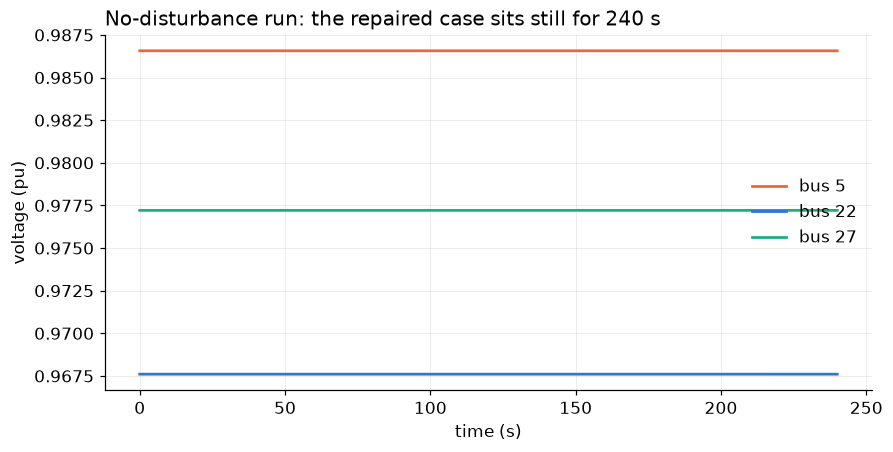

In [7]:
fig, ax = plt.subplots()
for b, colr in zip(['5', '22', '27'], [COL_2, COL_1, COL_3]):
    v = res.getBus(b).mag
    ax.plot(v.time, v.value, color=colr, label=f'bus {b}')
ax.set_xlabel('time (s)')
ax.set_ylabel('voltage (pu)')
ax.set_title('No-disturbance run: the repaired case sits still for 240 s', loc='left')
ax.legend(loc='center right')
plt.show()

## What you have seen

- **A false pass and how to avoid it.** `execSim()` returns normally after a divergence, so a
  run is checked by how far its trajectory got, not by whether it raised.
- **Three data faults behind one symptom**: LCC converter voltages that forced 70 degree
  angles, VSC links with no converter on DC-voltage control, and a power flow solved without
  the links it was meant to carry.
- **`M_` loads as a diagnostic.** Their size and location said exactly what the power flow
  left out: -500 MW at the EWIC terminal, -1000 MW at the Nemo terminal, the DC line losses.

### Things to try

- **Uncomment an event.** `disturb.dst` carries ready-made templates for a line trip, a
  machine trip, a bus fault and an HVDC control change.
- **Change a link's schedule.** Edit its constant load in `GBpf.dat`, re-solve with Helios,
  write `GBvoltrat.dat`, and set the matching powers in `GBhvdc.txt`.
- **Compare WT3 and WT4.** `WT4` is the full-converter machine, with no torque, pitch or
  aerodynamic blocks, so its rotor is decoupled from the grid.

### References

- [STEPSS model documentation](https://stepss.sps-lab.org/models/), for the WT3, WT4,
  HVDC_LCC and HVDC_VSC parameter lists
- [Power flow with Helios](https://stepss.sps-lab.org/python/helios/)
- [stepss Python API](https://stepss.sps-lab.org/python/)